# 01 · Limpieza y conciliación de la base de productoras

**Objetivo.** Dejar lista la base de 138 productoras (Norandino y Bagua Grande) que alimenta a los otros tres notebooks y al tablero.

**Qué hace este notebook**

1. Carga las dos hojas del formulario original y revisa su calidad: nulos, tipos, duplicados, texto inconsistente, valores atípicos e inconsistencias lógicas.
2. Explica y justifica cada decisión de limpieza.
3. Reconstruye los campos principales desde el original con reglas explícitas y los compara, campo por campo, con la base de referencia aprobada por el equipo.
4. Guarda la base limpia que usan los notebooks 02, 03 y 04.

| | Archivo |
|---|---|
| Entrada | `data/raw/Base de Datos Nor-BG anónima.xlsx` (hojas `Productoras Norandino` y `Productoras Bagua Grande`) |
| Entrada | `data/processed/Base_Nor_BG_limpia.xlsx` (hoja `Productoras`, referencia aprobada) |
| Salida | `data/processed/productoras_limpia.csv` |
| Salida | `data/processed/diagnostico_calidad.csv` y `data/processed/conciliacion_campos.csv` |

In [1]:
from pathlib import Path
import re
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Raíz del proyecto: el notebook funciona abierto desde la raíz o desde notebooks/
ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
RAW = ROOT / "data" / "raw" / "Base de Datos Nor-BG anónima.xlsx"
REF = ROOT / "data" / "processed" / "Base_Nor_BG_limpia.xlsx"
OUT = ROOT / "data" / "processed"
FIG = ROOT / "docs" / "figuras"
FIG.mkdir(parents=True, exist_ok=True)

# Colores fijos por cooperativa, los mismos que usa el tablero
COLORES = {"NORANDINO": "#2F5F9F", "BAGUA_GRANDE": "#8B5A2B"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10})
pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_colwidth", 60)

## 1. Carga de los datos originales

Cada hoja es un formulario distinto: los encabezados están en la fila 3 y los datos empiezan en la fila 4. Se agregan tres columnas de trazabilidad (cooperativa, hoja y fila del Excel original) para poder volver siempre al dato de origen.

In [2]:
def sin_tildes(t):
    """Quita tildes para comparar textos sin depender de cómo se escribió."""
    return "".join(c for c in unicodedata.normalize("NFD", str(t)) if unicodedata.category(c) != "Mn")

def cargar_hoja(hoja, cooperativa):
    crudo = pd.read_excel(RAW, sheet_name=hoja, header=None)
    encabezados = [re.sub(r"\s+", " ", str(x)).strip() for x in crudo.iloc[2]]
    datos = crudo.iloc[3:].copy()
    datos.columns = encabezados
    datos["cooperativa"] = cooperativa
    datos["hoja_origen"] = hoja
    datos["fila_excel_origen"] = datos.index + 1   # el índice de pandas parte en 0; el Excel, en 1
    return datos

nor = cargar_hoja("Productoras Norandino", "NORANDINO")
bg = cargar_hoja("Productoras Bagua Grande", "BAGUA_GRANDE")
print(f"Norandino: {nor.shape[0]} filas x {nor.shape[1]} columnas")
print(f"Bagua Grande: {bg.shape[0]} filas x {bg.shape[1]} columnas")
print("Total de productoras:", len(nor) + len(bg))

Norandino: 113 filas x 46 columnas
Bagua Grande: 25 filas x 42 columnas
Total de productoras: 138


## 2. Diagnóstico de calidad

Se revisan seis problemas posibles. Cada hallazgo se cuantifica y se guarda en una tabla resumen (sección 2.7).

### 2.1 Datos faltantes

Un vacío puede significar tres cosas distintas: la pregunta no existe en ese formulario, no aplica a la persona, o la persona no respondió. Por eso se cuentan los nulos **por hoja**, solo sobre las preguntas que cada formulario sí hizo.

Celdas vacías en total (ambas hojas): 197


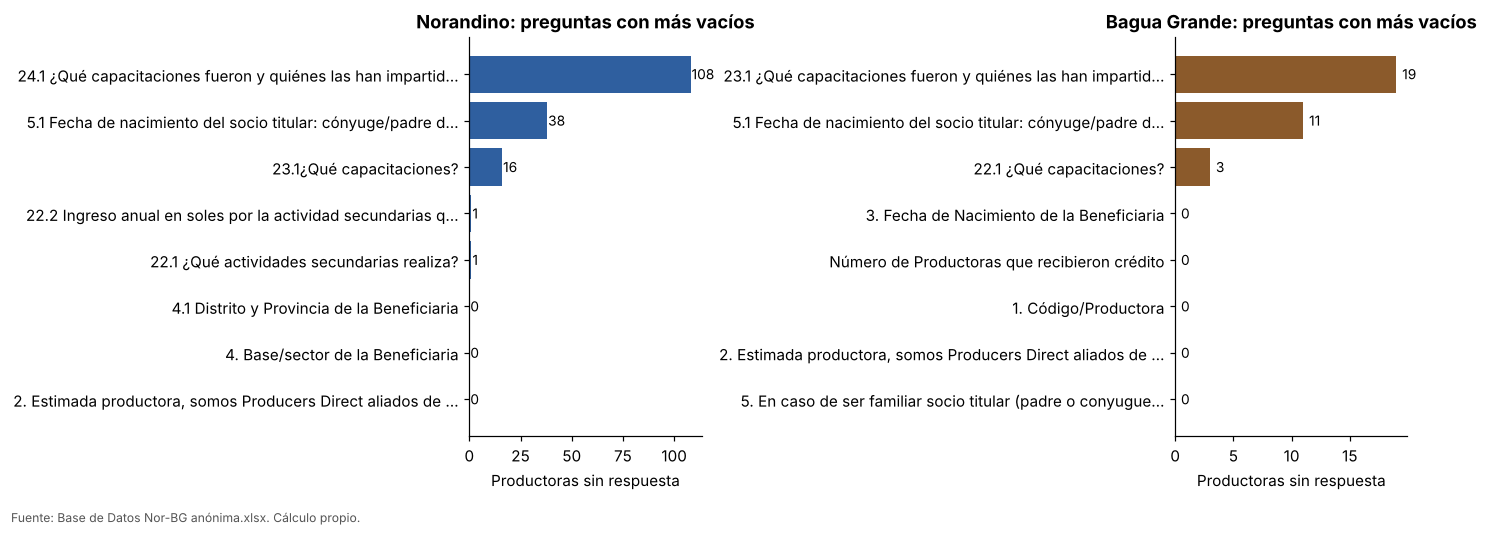

In [3]:
def nulos_por_columna(df):
    cols = [c for c in df.columns if c not in ("cooperativa", "hoja_origen", "fila_excel_origen")]
    t = pd.DataFrame({"nulos": df[cols].isna().sum()})
    t["pct"] = (100 * t["nulos"] / len(df)).round(1)
    t["pregunta"] = [c[:58] + ("…" if len(c) > 58 else "") for c in t.index]
    return t.sort_values("nulos", ascending=False)

nulos_nor, nulos_bg = nulos_por_columna(nor), nulos_por_columna(bg)
total_nulos = int(nulos_nor["nulos"].sum() + nulos_bg["nulos"].sum())
print("Celdas vacías en total (ambas hojas):", total_nulos)

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.8), sharex=False)
for eje, t, nombre in ((ejes[0], nulos_nor, "NORANDINO"), (ejes[1], nulos_bg, "BAGUA_GRANDE")):
    top = t.head(8).iloc[::-1]
    eje.barh(top["pregunta"], top["nulos"], color=COLORES[nombre])
    for y, v in enumerate(top["nulos"]):
        eje.text(v + 0.5, y, str(int(v)), va="center", fontsize=9)
    eje.set_title(f"{nombre.title().replace('_', ' ')}: preguntas con más vacíos")
    eje.set_xlabel("Productoras sin respuesta")
fig.text(0.01, 0.0, "Fuente: Base de Datos Nor-BG anónima.xlsx. Cálculo propio.", fontsize=8, color="#555")
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

In [4]:
# Columnas que usan los indicadores del proyecto: ¿tienen vacíos?
clave = {"Año de nacimiento": r"^3\. Fecha de Nacimiento", "Familiares que viven": r"^6\. Numero",
         "Antigüedad de asociada": r"^7\. Tiempo de asociado", "Área de café": r"^9\. Area",
         "Quintales acopiados": r"^10\. Quintales", "Monto solicitado": r"Monto requerido",
         "Ingreso principal": r"^(25|20)\. Ingreso anual"}
filas = []
for etiqueta, patron in clave.items():
    fila = {"variable": etiqueta}
    for nombre, df in (("NORANDINO", nor), ("BAGUA_GRANDE", bg)):
        c = [x for x in df.columns if re.search(patron, sin_tildes(x), re.I)][0]
        fila[nombre] = int(df[c].isna().sum())
    filas.append(fila)
pd.DataFrame(filas).set_index("variable")

,NORANDINO,BAGUA_GRANDE
variable,,
Año de nacimiento,0,0
Familiares que viven,0,0
Antigüedad de asociada,0,0
Área de café,0,0
Quintales acopiados,0,0
Monto solicitado,0,0
Ingreso principal,0,0


**Lectura.** Los vacíos se concentran en preguntas opcionales o condicionales (detalle de capacitaciones, actividades secundarias, fecha de nacimiento del socio titular cuando la beneficiaria es la titular). Las siete variables que alimentan el análisis cuantitativo no tienen vacíos en ninguna de las dos hojas, así que **no hace falta imputar valores** para calcular los indicadores.

### 2.2 Tipos de dato

Las preguntas numéricas deben traer solo números. Se cuentan las celdas que no se pueden convertir.

In [5]:
numericas = {"Familiares que viven": r"^6\. Numero", "Antigüedad de asociada": r"^7\. Tiempo de asociado",
             "Área de café": r"^9\. Area", "Quintales acopiados": r"^10\. Quintales",
             "Monto solicitado": r"Monto requerido", "Ingreso principal": r"^(25|20)\. Ingreso anual"}
filas = []
for etiqueta, patron in numericas.items():
    malas = 0
    for df in (nor, bg):
        c = [x for x in df.columns if re.search(patron, sin_tildes(x), re.I)][0]
        convertido = pd.to_numeric(df[c], errors="coerce")
        malas += int((df[c].notna() & convertido.isna()).sum())
    filas.append({"variable": etiqueta, "celdas con texto en lugar de número": malas})
tipos = pd.DataFrame(filas).set_index("variable")
tipos

,celdas con texto en lugar de número
variable,
Familiares que viven,0
Antigüedad de asociada,0
Área de café,0
Quintales acopiados,0
Monto solicitado,0
Ingreso principal,0


**Lectura.** Ninguna pregunta numérica trae texto: los importes, el área y los quintales llegan como números y no se necesita convertirlos. La fecha de nacimiento sí llega como fecha de Excel y se usa para calcular la edad.

### 2.3 Duplicados

In [6]:
todo = pd.concat([nor, bg], ignore_index=True)
cod_col = [c for c in todo.columns if c.startswith("1. Codigo") or c.startswith("1. Código")][0]
codigos = todo[cod_col].astype("string").str.strip()
print("Códigos de productora repetidos:", int(codigos.duplicated().sum()))
print("Filas totalmente repetidas:", int(todo.drop(columns=["fila_excel_origen"]).duplicated().sum()))
print("Códigos vacíos:", int(codigos.isna().sum()))
print("Códigos con formato PD-FR-###-FF-NOR/BG:", int(codigos.str.match(r"^PD-FR-\d{3}-FF-(NOR|BG)$").sum()), "de", len(codigos))

Códigos de productora repetidos: 0
Filas totalmente repetidas: 0
Códigos vacíos: 0
Códigos con formato PD-FR-###-FF-NOR/BG: 138 de 138


### 2.4 Texto inconsistente

Se busca texto con espacios sobrantes o escrito de varias formas, que haría que una misma respuesta se cuente como dos categorías.

In [7]:
texto = todo.select_dtypes(include=["object", "string"]).drop(columns=["cooperativa", "hoja_origen"], errors="ignore")
con_espacios = texto.apply(lambda s: s.astype("string").str.contains(r"^\s|\s$|\s{2,}", regex=True, na=False))
print("Celdas de texto con espacios sobrantes:", int(con_espacios.values.sum()))
print("Columnas afectadas:", int((con_espacios.sum() > 0).sum()), "de", texto.shape[1])

# ¿Alguna pregunta cambia de número de categorías al normalizar los espacios?
cambios = []
for c in texto.columns:
    antes = texto[c].astype("string")
    despues = antes.str.replace(r"\s+", " ", regex=True).str.strip()
    if antes.nunique() != despues.nunique():
        cambios.append({"pregunta": c[:60], "variantes antes": antes.nunique(), "variantes después": despues.nunique()})
pd.DataFrame(cambios)

Celdas de texto con espacios sobrantes: 939
Columnas afectadas: 21 de 70


,pregunta,variantes antes,variantes después
0,4. Base/sector de la Beneficiaria,24,23


**Lectura.** Muchas respuestas traen espacios al inicio, al final o dobles (por ejemplo `"Smartphone "`). Casi siempre no duplican categorías, pero en la pregunta de base o sector sí: una misma base aparece escrita de dos maneras. Se normalizan los espacios en todo el texto y se unifican las categorías con una regla explícita (sección 4), para que ninguna comparación falle por un espacio.

### 2.5 Valores atípicos

Se usa la regla del rango intercuartílico (IQR): un valor es atípico si queda por debajo de Q1 − 1.5·IQR o por encima de Q3 + 1.5·IQR. Es una señal para revisar, no una orden de eliminar.

In [8]:
def serie(patron):
    partes = []
    for df in (nor, bg):
        c = [x for x in df.columns if re.search(patron, sin_tildes(x), re.I)][0]
        partes.append(pd.to_numeric(df[c], errors="coerce"))
    return pd.concat(partes, ignore_index=True)

vars_iqr = {"Área de café": serie(r"^9\. Area"), "Quintales acopiados": serie(r"^10\. Quintales"),
            "Monto solicitado (S/)": serie(r"Monto requerido"), "Ingreso principal (S/)": serie(r"^(25|20)\. Ingreso anual"),
            "Familiares que viven": serie(r"^6\. Numero"), "Antigüedad (años)": serie(r"^7\. Tiempo de asociado")}
filas = []
for nombre, s in vars_iqr.items():
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    inf, sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    # Si IQR = 0 casi todos los valores son iguales y la regla marcaría todo lo distinto: no se aplica
    atipicos = int(((s < inf) | (s > sup)).sum()) if iqr > 0 else np.nan
    filas.append({"variable": nombre, "Q1": q1, "Q3": q3, "IQR": iqr, "límite inferior": inf, "límite superior": sup,
                  "atípicos": atipicos, "máximo": s.max()})
iqr_tabla = pd.DataFrame(filas).set_index("variable").round(2)
iqr_tabla

,Q1,Q3,IQR,límite inferior,límite superior,atípicos,máximo
variable,,,,,,,
Área de café,2.0,2.5,0.5,1.25,3.25,29.0,6.0
Quintales acopiados,25.0,45.0,20.0,-5.00,75.00,12.0,150.0
Monto solicitado (S/),1375.0,1375.0,0.0,1375.00,1375.00,NaN,2000.0
Ingreso principal (S/),25000.0,40000.0,15000.0,2500.00,62500.00,10.0,180000.0
Familiares que viven,3.0,4.0,1.0,1.50,5.50,13.0,8.0
Antigüedad (años),2.0,6.0,4.0,-4.00,12.00,15.0,45.0


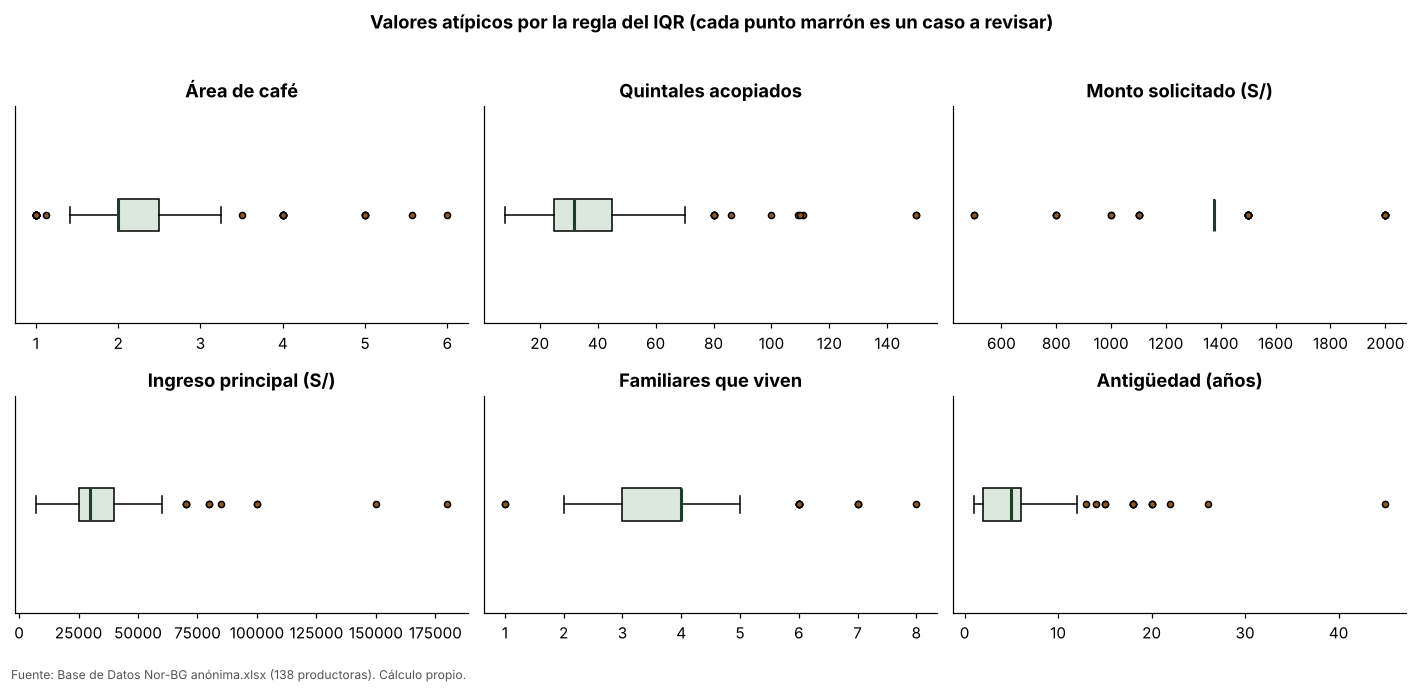

In [9]:
fig, ejes = plt.subplots(2, 3, figsize=(13, 6.2))
for eje, (nombre, s) in zip(ejes.ravel(), vars_iqr.items()):
    eje.boxplot(s.dropna(), orientation="horizontal", patch_artist=True, boxprops={"facecolor": "#DCE8DD"},
                medianprops={"color": "#1F3D2B", "linewidth": 2}, flierprops={"markerfacecolor": "#8B5A2B", "markersize": 4})
    eje.set_title(nombre)
    eje.set_yticks([])
fig.suptitle("Valores atípicos por la regla del IQR (cada punto marrón es un caso a revisar)", fontweight="bold")
fig.text(0.01, 0.0, "Fuente: Base de Datos Nor-BG anónima.xlsx (138 productoras). Cálculo propio.", fontsize=8, color="#555")
plt.tight_layout(rect=(0, 0.03, 1, 0.96))
plt.show()

**Lectura.** Hay atípicos en área, quintales, ingreso, familiares y antigüedad, casi todos hacia arriba: son fincas o ingresos más grandes que la mayoría. En el monto solicitado la regla no se aplica: casi todas piden lo mismo (IQR = 0), y marcar todo lo distinto no tendría sentido. Son valores posibles en una cooperativa cafetalera, no errores de digitación, así que **se conservan y se marcan** en lugar de borrarlos o recortarlos. Por eso los indicadores del proyecto usan la mediana, que no se distorsiona con ellos.

### 2.6 Inconsistencias lógicas

Tres reglas de sentido común: (a) quien dice "Ninguno" no puede usar un servicio financiero; (b) un padre debe ser bastante mayor que su hija; (c) no puede haber importes negativos ni edades imposibles.

In [10]:
# (a) Servicios financieros contradictorios
c_serv = [c for c in todo.columns if "servicios financieros utiliza" in c]
serv = pd.concat([nor[[c for c in nor.columns if "servicios financieros utiliza" in c][0]],
                  bg[[c for c in bg.columns if "servicios financieros utiliza" in c][0]]], ignore_index=True).astype("string").str.lower()
contradictorio = serv.str.contains("ningun") & serv.str.contains(r"yape|plin|cuenta|caja|banc")
cod_contra = codigos[contradictorio].tolist()
print("(a) 'Ninguno' junto con otro servicio:", len(cod_contra), cod_contra)

# (b) Parentesco "padre" con diferencia de edad menor a 12 años
def edad_dif(df):
    par = df[[c for c in df.columns if c.startswith("5. En caso")][0]].astype("string").str.lower()
    nac_b = pd.to_datetime(df[[c for c in df.columns if c.startswith("3. Fecha")][0]], errors="coerce")
    nac_t = pd.to_datetime(df[[c for c in df.columns if c.startswith("5.1")][0]], errors="coerce")
    dif = (nac_b - nac_t).dt.days / 365.25      # positivo = el titular es mayor
    return pd.DataFrame({"codigo": df[cod_col].astype("string").str.strip(), "parentesco": par, "dif_anios": dif})
dif = pd.concat([edad_dif(nor), edad_dif(bg)], ignore_index=True)
padres = dif[dif["parentesco"].str.contains("padre", na=False)]
padre_raro = padres[padres["dif_anios"] < 12]
print(f"(b) Declarados como padre: {len(padres)}; con menos de 12 años de diferencia: {len(padre_raro)}")
print(padre_raro.round(1).to_string(index=False))

# (c) Importes negativos y edades fuera de rango
edad = (pd.Timestamp("2025-12-31") - pd.concat([pd.to_datetime(nor[[c for c in nor.columns if c.startswith("3. Fecha")][0]]),
        pd.to_datetime(bg[[c for c in bg.columns if c.startswith("3. Fecha")][0]])], ignore_index=True)).dt.days / 365.2425
negativos = sum(int((s < 0).sum()) for s in vars_iqr.values())
print("(c) Valores negativos:", negativos, "| edades fuera de 18–90:", int(((edad < 18) | (edad > 90)).sum()),
      "| rango de edad:", round(edad.min()), "a", round(edad.max()), "años")

(a) 'Ninguno' junto con otro servicio: 1 ['PD-FR-121-FF-BG']
(b) Declarados como padre: 7; con menos de 12 años de diferencia: 3
          codigo parentesco  dif_anios
PD-FR-016-FF-NOR      padre      -22.3
PD-FR-078-FF-NOR      padre      -25.3
PD-FR-106-FF-NOR      padre      -17.2
(c) Valores negativos: 0 | edades fuera de 18–90: 0 | rango de edad: 19 a 89 años


**Lectura.** Hay un caso de servicios contradictorios (declara "Ninguno" y "Yape" a la vez) y varios casos de "padre" con una diferencia de edad que no cuadra con ese parentesco. En ninguno de los dos casos se puede saber cuál dato es el correcto, así que **no se corrige ni se elimina**: se conservan los valores tal como llegaron, se marcan para que Producers Direct confirme, y quedan en la hoja `Revision` de la base de referencia.

### 2.7 Resumen del diagnóstico

In [11]:
diagnostico = pd.DataFrame([
    {"problema": "Registros cargados", "cuántos": len(todo), "dónde": "113 Norandino y 25 Bagua Grande", "gravedad": "Informativo", "decisión": "Se conservan todos"},
    {"problema": "Códigos duplicados", "cuántos": int(codigos.duplicated().sum()), "dónde": "—", "gravedad": "Ninguna", "decisión": "Sin acción"},
    {"problema": "Celdas vacías en preguntas del formulario", "cuántos": total_nulos, "dónde": "Preguntas opcionales o condicionales", "gravedad": "Baja", "decisión": "No se imputan; se distingue pregunta ausente de dato faltante"},
    {"problema": "Vacíos en las siete variables numéricas del análisis", "cuántos": 0, "dónde": "—", "gravedad": "Ninguna", "decisión": "Sin acción"},
    {"problema": "Celdas de texto con espacios sobrantes", "cuántos": int(con_espacios.values.sum()), "dónde": f"{int((con_espacios.sum() > 0).sum())} columnas", "gravedad": "Media", "decisión": "Se normalizan espacios y categorías"},
    {"problema": "Valores atípicos por IQR (5 variables; en monto no aplica)", "cuántos": int(iqr_tabla["atípicos"].sum()), "dónde": "Área, quintales, ingreso, familiares, antigüedad", "gravedad": "Media", "decisión": "Se conservan y se marcan; los indicadores usan mediana"},
    {"problema": "Servicios financieros contradictorios", "cuántos": len(cod_contra), "dónde": ", ".join(cod_contra), "gravedad": "Media", "decisión": "Se conserva el dato, se marca y se consulta a Producers Direct"},
    {"problema": "Padre con diferencia de edad menor a 12 años", "cuántos": len(padre_raro), "dónde": ", ".join(padre_raro["codigo"].astype(str)), "gravedad": "Media", "decisión": "No se intercambian fechas; se marca para confirmar"},
    {"problema": "Valores negativos o edades imposibles", "cuántos": negativos + int(((edad < 18) | (edad > 90)).sum()), "dónde": "—", "gravedad": "Ninguna", "decisión": "Sin acción"},
])
diagnostico.to_csv(OUT / "diagnostico_calidad.csv", index=False, encoding="utf-8-sig")
diagnostico

,problema,cuántos,dónde,gravedad,decisión
0,Registros cargados,138,113 Norandino y 25 Bagua Grande,Informativo,Se conservan todos
1,Códigos duplicados,0,—,Ninguna,Sin acción
2,Celdas vacías en preguntas del formulario,197,Preguntas opcionales o condicionales,Baja,No se imputan; se distingue pregunta ausente de dato fal...
3,Vacíos en las siete variables numéricas del análisis,0,—,Ninguna,Sin acción
4,Celdas de texto con espacios sobrantes,939,21 columnas,Media,Se normalizan espacios y categorías
5,Valores atípicos por IQR (5 variables; en monto no aplica),79,"Área, quintales, ingreso, familiares, antigüedad",Media,Se conservan y se marcan; los indicadores usan mediana
6,Servicios financieros contradictorios,1,PD-FR-121-FF-BG,Media,"Se conserva el dato, se marca y se consulta a Producers ..."
7,Padre con diferencia de edad menor a 12 años,3,"PD-FR-016-FF-NOR, PD-FR-078-FF-NOR, PD-FR-106-FF-NOR",Media,No se intercambian fechas; se marca para confirmar
8,Valores negativos o edades imposibles,0,—,Ninguna,Sin acción


## 3. Decisiones de limpieza y su justificación

| Decisión | Criterio | Por qué |
|---|---|---|
| Normalizar espacios y mayúsculas en el texto | Misma respuesta, una sola categoría | Evita contar dos veces la misma respuesta |
| Convertir respuestas de texto en categorías estándar (`SMARTPHONE`, `TECLAS`, `NINGUNO`, etc.) | Regla escrita y comprobable | Permite filtrar y comparar entre cooperativas |
| No imputar datos faltantes | No se inventan valores | Un vacío en una pregunta opcional no equivale a cero ni a "No" |
| Conservar los valores atípicos y marcarlos | Rango intercuartílico como señal | Son valores posibles; borrarlos sesgaría los totales |
| Conservar los casos contradictorios sin corregir | Se marcan y se consultan | No hay forma de saber cuál de los dos datos es el correcto |
| No convertir unidades del área ni del quintal | La unidad no está confirmada por la cooperativa | Convertir sin confirmar crearía un error silencioso |
| Edad calculada al 31/12/2025 | Corte fijo | No se conoce la fecha exacta de la encuesta |
| No guardar la fecha de nacimiento en la base de salida | Solo se conserva la edad | Reduce datos personales: la edad basta para el análisis |

Todos los cambios son reversibles: la base original no se modifica y cada fila conserva la hoja y la fila de origen.

## 4. Reconstrucción de los campos desde el original

Se aplican las reglas de la sección 3 a las dos hojas y se arma una tabla común. Los dos formularios numeran sus preguntas distinto, por eso se buscan las columnas por el texto de la pregunta y no por su posición.

In [12]:
def col(df, patron):
    """Busca la única columna cuyo encabezado coincide con el patrón (sin tildes)."""
    hallada = [c for c in df.columns if re.search(patron, sin_tildes(c), re.I)]
    assert len(hallada) == 1, f"Se esperaba una columna para {patron!r}: {hallada}"
    return df[hallada[0]]

def txt(s):
    return s.astype("string").str.replace(r"\s+", " ", regex=True).str.strip()

def num(s):
    return pd.to_numeric(s, errors="coerce")

def servicios(valor):
    """Convierte la respuesta libre en una lista ordenada de servicios estándar."""
    if pd.isna(valor):
        return pd.NA
    t = sin_tildes(valor).lower()
    hallados = []
    for etiqueta, patron in (("CAJA_AHORRO", r"caja"), ("CUENTA_BANCARIA", r"cuenta|banc"), ("NINGUNO", r"ningun"),
                             ("PLIN", r"plin"), ("YAPE", r"yape")):
        if re.search(patron, t):
            hallados.append(etiqueta)
    return "; ".join(sorted(hallados))

def categoria(valor, reglas):
    """Devuelve la primera categoría cuyo patrón aparece en el texto."""
    if pd.isna(valor):
        return pd.NA
    t = sin_tildes(valor).lower()
    for etiqueta, patron in reglas:
        if re.search(patron, t):
            return etiqueta
    return pd.NA

REGLAS_CELULAR = [("SMARTPHONE", r"smartphone"), ("TECLAS", r"teclas"), ("NINGUNO", r"no tengo")]
REGLAS_LECTURA = [("NINGUNA", r"no no tengo ninguna"), ("AMBAS", r"ambos"), ("SOLO_LECTURA", r"solo para leer"),
                  ("SOLO_ESCRITURA", r"solo para escribir")]
REGLAS_PARENTESCO = [("PADRE", r"padre"), ("CONYUGE", r"conyug"), ("TITULAR", r"titular|ninguno")]
REGLAS_EDUCACION = [("NINGUNO", r"^ninguno"), ("PRIMARIA_INCOMPLETA", r"primaria incompleta"), ("PRIMARIA_COMPLETA", r"primaria completa"),
                    ("SECUNDARIA_INCOMPLETA", r"secundaria incompleta"), ("SECUNDARIA_COMPLETA", r"secundaria completa"),
                    ("TECNICO_COMPLETO", r"tecnic")]

def reconstruir(df):
    o = pd.DataFrame(index=df.index)
    o["codigo_productora"] = txt(col(df, r"^1\. Codigo"))
    o["cooperativa"] = df["cooperativa"]
    lugar = txt(col(df, r"^4\.1 Distrito")).str.split(r"\s*-\s*", n=1, expand=True)
    o["distrito"], o["provincia"] = lugar[0].str.strip(), lugar[1].str.strip()
    nacimiento = pd.to_datetime(col(df, r"^3\. Fecha de Nacimiento"), errors="coerce")
    o["edad_al_cierre_2025"] = (pd.Timestamp("2025-12-31") - nacimiento).dt.days // 365.2425
    o["n_familiares_convivientes"] = num(col(df, r"^6\. Numero de miembros"))
    o["antiguedad_socio_titular_anios"] = num(col(df, r"^7\. Tiempo de asociado"))
    o["area_cafe_reportada"] = num(col(df, r"^9\. Area de cultivo"))
    o["quintales_acopiados_2025"] = num(col(df, r"^10\. Quintales"))
    o["monto_solicitado_pen"] = num(col(df, r"Monto requerido en soles"))
    o["ingreso_principal_pen_2025"] = num(col(df, r"^(25|20)\. Ingreso anual"))
    o["parentesco_socio_titular"] = col(df, r"^5\. En caso").map(lambda v: categoria(v, REGLAS_PARENTESCO))
    o["tipo_celular_beneficiaria"] = col(df, r"tiene smartphone y/o celular").map(lambda v: categoria(v, REGLAS_CELULAR))
    o["dificultad_lectoescritura"] = col(df, r"dificultades para leer").map(lambda v: categoria(v, REGLAS_LECTURA))
    o["nivel_educativo"] = col(df, r"Nivel o grado educativo").map(lambda v: categoria(v, REGLAS_EDUCACION))
    o["servicios_financieros"] = col(df, r"servicios financieros utiliza").map(servicios)
    o["capacitacion_cooperativa_2025"] = col(df, r"capacitacion de la cooperativa|actividades de capacitacion de la cooperativa").map(
        lambda v: pd.NA if pd.isna(v) else int(sin_tildes(v).strip().lower().startswith("si")))
    return o

recon = pd.concat([reconstruir(nor), reconstruir(bg)], ignore_index=True)
print(recon.shape)
recon.head(3)

(138, 17)


,codigo_productora,cooperativa,distrito,provincia,edad_al_cierre_2025,n_familiares_convivientes,antiguedad_socio_titular_anios,area_cafe_reportada,quintales_acopiados_2025,monto_solicitado_pen,ingreso_principal_pen_2025,parentesco_socio_titular,tipo_celular_beneficiaria,dificultad_lectoescritura,nivel_educativo,servicios_financieros,capacitacion_cooperativa_2025
0,PD-FR-001-FF-NOR,NORANDINO,Tabaconas,San Ignacio,31.0,5,5,2.5,23,1375,30000,TITULAR,SMARTPHONE,NINGUNA,SECUNDARIA_INCOMPLETA,NINGUNO,1
1,PD-FR-002-FF-NOR,NORANDINO,Tabaconas,San Ignacio,58.0,2,2,3.5,109,1375,100000,TITULAR,SMARTPHONE,NINGUNA,PRIMARIA_COMPLETA,NINGUNO,1
2,PD-FR-003-FF-NOR,NORANDINO,Tabaconas,San Ignacio,39.0,2,5,2.4,50,1375,50000,CONYUGE,SMARTPHONE,NINGUNA,PRIMARIA_COMPLETA,NINGUNO,1


## 5. Conciliación con la base de referencia

La base `Base_Nor_BG_limpia.xlsx` (hoja `Productoras`, 77 columnas) es la referencia que el equipo revisó y aprobó. Se comparan, campo por campo, los valores reconstruidos aquí contra los de la referencia, uniendo por código de productora.

In [13]:
ref = pd.read_excel(REF, sheet_name="Productoras")
print("Referencia:", ref.shape, "| códigos únicos:", ref["codigo_productora"].nunique())

union = recon.merge(ref, on="codigo_productora", suffixes=("_aqui", "_ref"), validate="one_to_one")
print("Productoras unidas por código:", len(union))

def iguales(a, b):
    """Dos valores son iguales si coinciden, o si ambos están vacíos; números con tolerancia."""
    ambos_vacios = a.isna() & b.isna()
    if pd.api.types.is_numeric_dtype(b) and not pd.api.types.is_string_dtype(b):
        return ambos_vacios | ((pd.to_numeric(a, errors="coerce") - b).abs() < 1e-9)
    norm = lambda s: s.astype("string").map(lambda x: sin_tildes(x).upper().strip() if pd.notna(x) else x)
    return ambos_vacios | (norm(a) == norm(b))

campos = [c for c in recon.columns if c not in ("codigo_productora", "cooperativa")]
filas = []
for c in campos:
    ok = iguales(union[c + "_aqui"], union[c + "_ref"])
    filas.append({"campo": c, "coinciden": int(ok.sum()), "de": len(union), "% coincidencia": round(100 * ok.mean(), 1),
                  "casos distintos": ", ".join(union.loc[~ok, "codigo_productora"].head(3))})
conciliacion = pd.DataFrame(filas).set_index("campo")
conciliacion.to_csv(OUT / "conciliacion_campos.csv", encoding="utf-8-sig")
conciliacion

Referencia: (138, 77) | códigos únicos: 138
Productoras unidas por código: 138


,coinciden,de,% coincidencia,casos distintos
campo,,,,
distrito,138,138,100.0,
provincia,138,138,100.0,
edad_al_cierre_2025,138,138,100.0,
n_familiares_convivientes,138,138,100.0,
antiguedad_socio_titular_anios,138,138,100.0,
area_cafe_reportada,138,138,100.0,
quintales_acopiados_2025,138,138,100.0,
monto_solicitado_pen,138,138,100.0,
ingreso_principal_pen_2025,138,138,100.0,


In [14]:
total_ok = int(conciliacion["coinciden"].sum())
total = int(conciliacion["de"].sum())
print(f"Coincidencia global: {total_ok} de {total} celdas ({100 * total_ok / total:.2f}%)")
assert (conciliacion["% coincidencia"] == 100).all(), "Hay campos que no coinciden con la referencia; revisar la tabla anterior"

Coincidencia global: 2070 de 2070 celdas (100.00%)


**Lectura.** Los 15 campos reconstruidos desde el original coinciden al 100 % con la base de referencia, para las 138 productoras. Esto confirma que las reglas de la sección 3 son las que se aplicaron en la base aprobada, y que el proceso se puede repetir desde cero con los mismos resultados.

## 6. Base limpia final

Se toma la base de referencia completa (77 columnas, que además incluye los indicadores derivados y las banderas de revisión), se valida y se guarda como CSV para los notebooks siguientes. Se omiten las dos columnas de fecha de nacimiento; queda la edad.

In [15]:
base = ref.copy()

# Validaciones: si alguna falla, el notebook se detiene y no se guarda nada
assert len(base) == 138, "Se esperaban 138 productoras"
assert base["codigo_productora"].is_unique, "Hay códigos repetidos"
assert base["cooperativa"].value_counts().to_dict() == {"NORANDINO": 113, "BAGUA_GRANDE": 25}
for c in ("area_cafe_reportada", "quintales_acopiados_2025", "monto_solicitado_pen", "ingreso_principal_pen_2025"):
    assert base[c].notna().all() and (base[c] >= 0).all(), f"{c}: valores vacíos o negativos"
assert base["edad_al_cierre_2025"].between(18, 90).all()

# Las fechas de nacimiento no se guardan en la base de salida: ya se usaron para calcular la edad al cierre de 2025
fechas = [c for c in base.columns if c.startswith("fecha_nacimiento")]
salida = base.drop(columns=fechas)
salida.to_csv(OUT / "productoras_limpia.csv", index=False, encoding="utf-8-sig")
print("Columnas de fecha de nacimiento omitidas:", fechas)
print("Guardado:", (OUT / "productoras_limpia.csv").relative_to(ROOT), salida.shape)

Columnas de fecha de nacimiento omitidas: ['fecha_nacimiento_beneficiaria', 'fecha_nacimiento_familiar_titular']
Guardado: data/processed/productoras_limpia.csv (138, 75)


In [16]:
# Antes y después, en los totales que usa el tablero
resumen = pd.DataFrame({
    "indicador": ["Productoras", "Monto solicitado total (S/)", "Área de café total (unidad por confirmar)", "Quintales acopiados totales"],
    "original (aquí reconstruido)": [len(recon), recon["monto_solicitado_pen"].sum(), recon["area_cafe_reportada"].sum().round(2), recon["quintales_acopiados_2025"].sum()],
    "base limpia final": [len(base), base["monto_solicitado_pen"].sum(), base["area_cafe_reportada"].sum().round(2), base["quintales_acopiados_2025"].sum()],
}).set_index("indicador")
resumen

,original (aquí reconstruido),base limpia final
indicador,,
Productoras,138.00,138.00
Monto solicitado total (S/),190175.00,190175.00
Área de café total (unidad por confirmar),310.36,310.36
Quintales acopiados totales,5444.00,5444.00


## 7. Conclusión y paso siguiente

- Se revisaron seis tipos de problema de calidad; no hay duplicados, ni valores imposibles, ni vacíos en las variables numéricas del análisis.
- Los problemas reales son texto con espacios, valores atípicos legítimos y dos tipos de contradicción que solo Producers Direct puede aclarar.
- Ninguna decisión borra o inventa datos, y la reconstrucción desde el original coincide al 100 % con la base aprobada.
- Quedan por confirmar con la cooperativa la unidad del área, el peso del quintal y los casos marcados de parentesco y servicios.

**Siguiente:** `02_exploracion.ipynb` lee `data/processed/productoras_limpia.csv`.